# Aula 06 — Processos e Fontes de Dados (Teórica) · Conteúdo

**Unidade 2 — Aquisição e Preparação de Dados** · ver também: [exercícios](exercicios.ipynb) · [atividades](atividades.ipynb)

**📊 Aula 06 — Processos e Fontes de Dados (Teórica)**

Primeira aula da Unidade 2 (Aquisição e Preparação de Dados). Tipos de fontes de dados: arquivos, bancos de dados, APIs REST, web scraping; formatos (CSV, JSON, XML, Parquet, GeoJSON); questões de licença e proveniência. Exemplo prático com dados reais do Ministério da Saúde (CNES) e do IBGE, incluindo um mapa do Rio Grande do Norte. Recursos: slides, apostila em PDF, exemplo de consumo de API pública. Avaliação: exercício prático entregue no Moodle + formulário avaliativo com 10 questões — prazo de envio até 13/10/2026. Materiais desta aula: livro Tópicos de Estudo (6 capítulos) · apostila completa em PDF · slides · pacote com o exemplo de API e dados · exemplo prático comentado · tarefa de entrega · formulário avaliativo.

---
## Tópicos de Estudo — Aula 06: Processos e Fontes de Dados

### 1. Capítulo 1 — De onde vêm os dados: um panorama das fontes

Toda análise de dados começa antes da primeira linha de código: alguém precisa decidir **onde os dados moram** e **como trazê-los** para dentro do ambiente de trabalho. Esta aula cobre as quatro famílias de fontes mais comuns e os formatos que elas costumam falar.

#### As quatro famílias de fontes

- **Arquivos** — CSV, Excel, JSON, Parquet, XML, texto simples. A fonte mais previsível: o dado já está "parado", você só precisa lê-lo.
- **Bancos de dados** — sistemas como PostgreSQL, MySQL, SQL Server. O dado vive em tabelas relacionadas, e você conversa com ele por meio de SQL.
- **APIs REST** — um servidor remoto expõe endpoints HTTP que devolvem dados (normalmente em JSON) sob demanda, muitas vezes em tempo real.
- **Web scraping** — quando não existe arquivo, banco nem API, e a única forma de obter o dado é extraí-lo do HTML de uma página feita para humanos lerem, não para máquinas.

#### Por que a ordem acima não é aleatória

Ela reflete o quanto de **trabalho e risco** cada fonte exige. Um arquivo bem formado é a situação mais simples: leitura direta, sem rede, sem autenticação, sem terceiros. Um banco de dados exige uma conexão e permissões, mas ainda fala uma linguagem estruturada e estável (SQL). Uma API REST depende de um serviço de terceiros estar no ar, respeitar limites de uso e não mudar seu contrato sem aviso. Web scraping é o último recurso: você depende da estrutura visual de uma página, que pode mudar a qualquer redesign, e entra em território mais delicado do ponto de vista legal e ético (Capítulo 5).

#### Um exemplo real: o cadastro de estabelecimentos de saúde

Ao longo desta aula, o mesmo caso guia os quatro capítulos seguintes: o **CNES** (Cadastro Nacional de Estabelecimentos de Saúde), mantido pelo Ministério da Saúde. Os mesmos estabelecimentos de saúde do Rio Grande do Norte aparecem de quatro formas — como arquivo JSON salvo em disco, como tabela dentro de um banco SQLite, como resposta de uma API REST pública e ao lado de uma tabela raspada da Wikipédia — para que fique concreto o que muda (e o que não muda) de uma fonte para outra.

#### O ciclo de vida de um dado adquirido

Não basta "puxar" o dado uma vez. Um processo de aquisição saudável responde a quatro perguntas, sempre por escrito:

- **De onde veio?** (endpoint, URL, nome do arquivo, banco e tabela — a *proveniência*, tema do Capítulo 6)
- **Quando foi coletado?** (dados mudam; uma amostra de hoje pode não valer amanhã)
- **Sob que licença posso usá-lo?** (Capítulo 6 — nem todo dado público é dado livre)
- **O que fazer se a fonte mudar ou cair?** (arquivos de cache, versionamento, tratamento de erro)

As próximas aulas da Unidade 2 (limpeza, tratamento de dados ausentes, validação) partem do princípio de que os dados já chegaram até você de forma íntegra e rastreável — esta aula é o que garante essa base.

### 2. Capítulo 2 — Arquivos: a fonte mais simples (e onde ela falha)

Um arquivo bem-comportado é a fonte de dados mais fácil de usar: `pd.read_csv`, `pd.read_excel`, `pd.read_json` e pronto. Mas "bem-comportado" é a exceção, não a regra — a Aula 04 já mostrou isso com o CSV de matrículas do IFRN, cujo separador (`;`), decimal (`,`) e encoding (`utf-8`) precisaram ser declarados explicitamente.

#### As perguntas que todo arquivo exige

- **Qual o encoding?** `utf-8` é o padrão atual, mas arquivos exportados de sistemas legados brasileiros costumam vir em `latin-1` (também chamado `iso-8859-1`). Abrir com o encoding errado não gera erro imediato — gera acentos corrompidos ("informação" virando "informaÃ§Ã£o"), um bug silencioso e traiçoeiro.
- **Qual o separador e o decimal?** Planilhas brasileiras costumam usar `;` como separador de coluna (porque a vírgula já é o separador decimal) — o oposto do padrão americano.
- **A primeira linha é cabeçalho?** Nem sempre. Alguns exports incluem linhas de metadados ou títulos de relatório antes da tabela de fato (resolvido com `skiprows`).
- **O arquivo cabe na memória?** Um CSV de 50 GB não pode simplesmente virar um DataFrame inteiro — entram em cena leitura em blocos (`chunksize`) ou formatos colunares como Parquet.

#### Arquivo como cache de outra fonte

Uma prática comum — e usada no exemplo desta aula — é salvar em arquivo o resultado de uma chamada de API ou de uma consulta a banco:

In [ ]:
import json
with open("dados/cnes_rn_amostra.json", "w", encoding="utf-8") as f:
    json.dump(resposta_da_api, f, ensure_ascii=False, indent=1)

Isso transforma uma fonte instável e dependente de rede (API) em uma fonte estável e reproduzível (arquivo). O preço é que o arquivo é uma **fotografia**: se o cadastro do CNES mudar amanhã, o arquivo salvo hoje não vai refletir isso — por isso é essencial registrar a data da coleta junto com os dados (Capítulo 6).

#### Arquivos não são só "tabelas"

Um DataFrame é a abstração mais usada em ciência de dados, mas nem todo arquivo é tabular por natureza: um JSON aninhado (Capítulo 4), um XML com hierarquias profundas, ou um GeoJSON com polígonos de fronteiras territoriais (usado no mapa desta aula) exigem uma etapa de "achatamento" (*flattening*) antes de virarem linhas e colunas — por exemplo, com `pd.json_normalize`.

### 3. Capítulo 3 — Bancos de dados: quando o dado mora em tabelas relacionadas

Um banco de dados relacional guarda os dados em tabelas conectadas por chaves, e a forma de "puxar" dados dele não é um método de leitura de arquivo — é uma **consulta SQL**. A diferença central para arquivos e APIs: o banco pode processar, filtrar e juntar os dados *antes* de entregá-los, o que muitas vezes é bem mais eficiente do que trazer tudo para o Python e filtrar depois.

#### Conectando o Python a um banco

Cada banco tem seu driver (`psycopg2`/`psycopg` para PostgreSQL, `pymysql` para MySQL, `pyodbc` para SQL Server, o módulo `sqlite3` — da biblioteca padrão — para SQLite). O Pandas abstrai boa parte disso com duas funções:

In [ ]:
import sqlite3
import pandas as pd

conexao = sqlite3.connect("dados/exemplo.db")
df = pd.read_sql("SELECT * FROM estabelecimentos WHERE municipio = 'Natal'", conexao)

df.to_sql("estabelecimentos", conexao, index=False, if_exists="replace")

`read_sql` traz o resultado de uma consulta como DataFrame; `to_sql` faz o caminho inverso, gravando um DataFrame como tabela. É assim que o exemplo prático desta aula cria uma mini base SQLite em memória a partir dos dados do CNES e roda uma consulta agrupando estabelecimentos por município e tipo — o mesmo `GROUP BY` que a Aula 05 fez em Pandas, agora escrito em SQL.

#### SQL ou Pandas — quem faz o quê?

- Filtros, agregações e junções simples podem ser feitos em qualquer um dos dois — a régua é onde o dado já está e o volume envolvido.
- Se a tabela tem 200 milhões de linhas no banco, filtrar *dentro* do banco com `WHERE` antes de trazer o resultado para o Python evita transportar dados que serão descartados.
- Depois que o resultado já é pequeno e está em memória, Pandas costuma ser mais produtivo para exploração, limpeza e visualização.

#### Uma API também pode ser "um banco disfarçado"

Muitos serviços expõem, por trás de uma API REST, o mesmo tipo de filtro que um banco ofereceria (`WHERE codigo_municipio = ...` vira um parâmetro de URL). A diferença é que você não controla o schema, não pode fazer `JOIN` livremente entre tabelas do provedor, e está sujeito às regras de uso do serviço — o próximo capítulo detalha essa fonte.

### 4. Capítulo 4 — APIs REST: dados sob demanda, com regras do dono do serviço

Uma API REST é um contrato: o provedor define endereços (endpoints), parâmetros aceitos e o formato de resposta (quase sempre JSON); você faz requisições HTTP e recebe dados de volta. A biblioteca `requests` é o padrão em Python para isso.

#### Anatomia de uma requisição

In [ ]:
import requests

url = "https://apidadosabertos.saude.gov.br/cnes/estabelecimentos"
parametros = {"codigo_municipio": 240810, "limit": 20}
resposta = requests.get(url, params=parametros, timeout=10)
resposta.raise_for_status()
dados = resposta.json()

`params` vira a *query string* da URL (`?codigo_municipio=240810&limit=20`); `resposta.json()` converte o corpo da resposta (texto) em listas e dicionários Python; `raise_for_status()` levanta uma exceção se o servidor devolveu um código de erro (4xx ou 5xx) em vez/de sucesso (2xx).

#### Duas armadilhas reais, descobertas testando a API do CNES

- **Parâmetros aceitos silenciosamente, mas ignorados.** Tentar filtrar por `uf=RN` ou `codigo_uf=24` não gera erro — a API simplesmente devolve dados de qualquer estado, como se o filtro não existisse. Só o parâmetro correto (`codigo_municipio`, com o código IBGE de 6 dígitos) filtra de verdade. A lição: **sempre inspecionar o retorno**, nunca supor que um parâmetro "razoável" funcionou só porque não deu erro.
- **Limite de página fixo pelo servidor.** Pedir `limit=1000` devolve no máximo 20 registros — o servidor ignora limites maiores que o seu teto interno. Para reunir mais dados é preciso **paginar**, repetindo a chamada com `offset=20`, `offset=40`, e assim por diante, até a resposta vir vazia.

#### Autenticação e limites de uso (rate limiting)

A API usada nesta aula é pública e não exige chave de acesso — mas a maioria das APIs comerciais exige uma *API key* ou token OAuth, enviado em um cabeçalho HTTP (`headers={"Authorization": "Bearer ..."}`). Praticamente toda API pública impõe algum limite de requisições por minuto/hora (*rate limit*); ultrapassá-lo costuma devolver o código HTTP `429 Too Many Requests`. Um bom cliente de API trata isso com espera (*backoff*) e nova tentativa, em vez de martelar o servidor.

#### JSON aninhado precisa de "achatamento"

A resposta de uma API raramente já é uma tabela: é comum vir como uma lista de dicionários, às vezes com dicionários dentro de dicionários. `pd.json_normalize(dados["estabelecimentos"])` resolve o caso simples; estruturas mais profundas (como a API de municípios do IBGE, que aninha microrregião dentro de mesorregião dentro de UF) exigem escolher manualmente quais níveis "puxar" para colunas.

### 5. Capítulo 5 — Web scraping: o último recurso, com responsabilidade

Web scraping é extrair dados do HTML de uma página feita para ser lida por humanos, não consumida por máquinas. É a fonte mais frágil (qualquer redesign visual quebra o código) e a mais delicada do ponto de vista legal — por isso vem por último na lista, e só deve ser considerada quando não existe arquivo, banco ou API disponíveis.

#### Antes de escrever uma linha de código

- **Existe uma API para os mesmos dados?** Muitos sites que parecem exigir scraping têm uma API não documentada (visível na aba "Network" do navegador) ou uma API oficial — sempre vale procurar antes.
- **O que diz o `robots.txt`?** Todo site pode publicar em `/robots.txt` quais partes permite ou proíbe que robôs acessem. Não é uma barreira técnica, mas ignorá-lo é uma falta ética e, em alguns contextos, uma evidência de má-fé.
- **O que dizem os Termos de Uso?** Muitos sites proíbem explicitamente coleta automatizada, mesmo de páginas tecnicamente acessíveis. Termos de uso são um contrato — violá-los pode ter consequências, independentemente do robots.txt.
- **Sob que licença está o conteúdo?** Dado acessível não é dado livre para reuso (Capítulo 6).

#### Extraindo uma tabela com BeautifulSoup

In [ ]:
from bs4 import BeautifulSoup
import requests

html = requests.get("https://pt.wikipedia.org/wiki/...").text
sopa = BeautifulSoup(html, "html.parser")

tabela = sopa.find("table", {"class": "wikitable"})
linhas = []
for tr in tabela.find_all("tr")[1:]:
    colunas = [td.get_text(strip=True) for td in tr.find_all("td")]
    if colunas:
        linhas.append(colunas)

`find` localiza o primeiro elemento que casa com o seletor (aqui, uma tabela com a classe `wikitable`); `find_all` devolve todos os elementos que casam — aqui, todas as linhas (`tr`). `get_text(strip=True)` extrai o texto visível de cada célula, descartando as tags HTML.

#### Por que a Wikipédia é um bom laboratório para praticar

A Wikipédia publica seu conteúdo sob licença Creative Commons Atribuição-CompartilhaIgual (CC BY-SA), permite expressamente reuso — inclusive automatizado, dentro de limites razoáveis — e documenta isso claramente. É um dos poucos casos em que scraping educacional está sobre uma base legal e ética confortável. Ainda assim, boas práticas seguem valendo: identificar o seu programa no cabeçalho HTTP (*User-Agent*), espaçar as requisições no tempo e nunca sobrecarregar o servidor.

#### Fragilidade estrutural

Diferente de uma API, cujo contrato de dados é (em teoria) estável, uma página HTML pode ser redesenhada sem aviso — uma classe CSS renomeada quebra o scraper inteiro. Por isso scraping deve ser tratado como uma fonte de **último recurso** e, quando usado, isolado em um módulo próprio, fácil de consertar quando (não se) a página mudar.

### 6. Capítulo 6 — Formatos de dados, licença e proveniência

Depois de decidir a fonte, resta decidir (ou descobrir) o formato — e entender sob quais regras aquele dado pode ser usado. Os dois assuntos parecem distantes, mas aparecem juntos na prática: o formato afeta o quão fácil é registrar a proveniência de um dado, e a licença determina o que você tem permissão de fazer com ele depois de convertê-lo.

#### CSV — simples, universal, sem metadados

Texto puro, uma linha por registro, colunas separadas por um caractere (vírgula, ponto e vírgula, tabulação). Vantagem: qualquer ferramenta lê. Desvantagem: não guarda tipos (tudo é texto até alguém decidir o contrário), nem estrutura hierárquica, nem metadados sobre a fonte.

#### JSON — estrutura e aninhamento, sem tipagem de colunas

O formato padrão das APIs REST modernas: objetos (`{}`), listas (`[]`), pares chave-valor, aninhamento arbitrário. Permite representar estruturas que um CSV não representa bem (um estabelecimento com uma lista de serviços especializados, por exemplo) — mas exige "achatamento" para virar uma tabela (Capítulo 4). É comum — e recomendável — usar um JSON para guardar não só os dados, mas também metadados de proveniência (fonte, endpoint, data da coleta, licença), como neste exemplo:

In [ ]:
{
  "fonte": "Ministério da Saúde — API de Dados Abertos (CNES)",
  "endpoint": "https://apidadosabertos.saude.gov.br/cnes/estabelecimentos",
  "data_coleta": "2026-09-28",
  "licenca": "Dados abertos governamentais (Lei 12.527/2011)",
  "registros": [ ... ]
}

#### XML — a estrutura mais verbosa

Antecessor do JSON como formato de troca de dados na web, ainda comum em sistemas legados, notas fiscais eletrônicas e alguns webservices governamentais brasileiros. Usa tags abrindo e fechando (`<municipio>Natal</municipio>`), o que o torna bem mais verboso que JSON para representar o mesmo dado — no exemplo desta aula, os mesmos 3 registros em XML ocupam proporcionalmente mais espaço do que em JSON.

#### Parquet — formato colunar, feito para grandes volumes

Diferente de CSV e JSON (orientados a linha), o Parquet guarda os dados por coluna e de forma binária comprimida. Resultado: arquivos bem menores (no exemplo desta aula, o mesmo conjunto de 160 estabelecimentos ocupa menos espaço em Parquet do que em CSV, e uma fração do tamanho do JSON com metadados) e leitura seletiva de colunas sem precisar ler o arquivo inteiro. É o formato preferido para grandes volumes de dados tabulares no ecossistema de ciência de dados (Spark, pandas com PyArrow, data lakes).

#### GeoJSON — um caso especial de JSON para dados geográficos

Usado no mapa desta aula (contorno do Rio Grande do Norte, obtido da API de Malhas do IBGE): um JSON com uma estrutura padronizada para representar pontos, linhas e polígonos geográficos, com coordenadas de longitude e latitude. É o formato de troca padrão entre ferramentas de mapas (QGIS, Leaflet, geopandas).

#### Licença: o que você pode fazer com o dado

- **Dados públicos governamentais brasileiros** (como o CNES e o IBGE, usados nesta aula) são regidos pela **Lei de Acesso à Informação** (Lei 12.527/2011) e por políticas de dados abertos — via de regra, uso livre, inclusive comercial, com boa prática de citar a fonte.
- **Creative Commons (CC)** — família de licenças usada por Wikipédia (CC BY-SA, usada nesta aula), bancos de imagens e alguns datasets acadêmicos. As variações importam: `BY` exige atribuição, `SA` (*share-alike*) exige que derivados usem a mesma licença, `NC` proíbe uso comercial, `ND` proíbe modificações.
- **Termos de uso proprietários** — comuns em APIs comerciais e redes sociais: podem proibir redistribuição, uso comercial, ou exigir que os dados sejam apagados após um prazo.
- **Ausência de licença explícita** não significa domínio público — na dúvida, o dado deve ser tratado como protegido por padrão.

#### Proveniência: a rastreabilidade que sustenta a confiança

Um dado sem proveniência registrada é, na prática, inutilizável para qualquer decisão séria: ninguém pode auditar, reproduzir ou saber se ainda é válido. Registrar proveniência custa poucas linhas (como no JSON acima) e paga dividendo toda vez que alguém — inclusive você, seis meses depois — precisar responder "de onde veio esse número?".

---
## Conteúdo — Aula 06: Processos e Fontes de Dados (apostila em PDF)

> Convertido de [`Aula06_Fontes_de_Dados.pdf`](Aula06_Fontes_de_Dados.pdf) (o original está nesta pasta — confira nele figuras e diagramação).

INSTITUTO FEDERAL DE EDUCAÇÃO, CIÊNCIA E TECNOLOGIA DO RIO GRANDE DO NORTE ESPECIALIZAÇÃO EM CIÊNCIA DE DADOS  ·  DISCIPLINA: ANÁLISE E CIÊNCIA DE DADOS

### Aula 06 - Processos e Fontes de Dados

Arquivos, bancos de dados, APIs REST e web scraping; formatos CSV/JSON/XML/Parquet/GeoJSON; licença e proveniência de dados

Unidade

Natureza Unidade 2 - Aquisição e Preparação de Dados (Aula 06, primeira aula)

Aula teórico-prática

Carga horária

4 h/a - 2 h de exposição guiada + 2 h de laboratório

Pré-

requisitos

Recursos

Avaliação Aulas 04-05 - DataFrames, leitura de CSV/Excel, groupby/agg/merge em Pandas Jupyter Notebook/Lab, pandas , requests , beautifulsoup4 , sqlite3 (biblioteca padrão), pyarrow Exercício prático entregue no Moodle + formulário avaliativo (10 questões)

Professor Plácido Antônio de Souza Neto

### Objetivos de aprendizagem

Ao final desta aula, espera-se que o estudante seja capaz de:

1. Identificar e diferenciar as quatro famílias de fontes de dados (arquivos, bancos de dados, APIs REST e web scraping), escolhendo entre elas a partir do que está disponível e do risco envolvido em cada uma.
2. Ler e escrever dados nos formatos CSV, JSON, XML e Parquet com Pandas, reconhecendo as vantagens e limitações de cada um.
3. Reconhecer o GeoJSON como um formato de dados geográficos e interpretar seu uso na construção de um mapa simples.
4. Consumir uma API REST real com a biblioteca requests , incluindo o envio de parâmetros, a checagem de erros com raise\_for\_status() e a leitura da resposta em JSON.
5. Implementar paginação de uma API que limita o tamanho de cada resposta, usando um parâmetro de deslocamento ( offset ).
6. Gravar e consultar dados em um banco SQLite a partir do Pandas, com to\_sql , read\_sql e uma consulta SQL com GROUP BY .
7. Realizar web scraping responsável com BeautifulSoup, incluindo a verificação prévia de robots.txt e termos de uso.
8. Explicar a diferença entre licença e proveniência de um conjunto de dados, e registrar essas informações junto aos dados coletados.

### Sumário

### Parte I - Fundamentos teóricos

- 1.1 De onde vêm os dados: um panorama das fontes
- 1.2 Arquivos: a fonte mais simples (e onde ela falha)
- 1.3 Bancos de dados: quando o dado mora em tabelas relacionadas
- 1.4 APIs REST: dados sob demanda, com regras do dono do serviço
- 1.5 Web scraping: o último recurso, com responsabilidade
- 1.6 Formatos de dados, licença e proveniência

### Parte II - Tópicos de estudo dirigido (roteiro de leitura)

- Parte III - Laboratório guiado: estabelecimentos de saúde do RN (CNES)

Parte IV - Exercício prático avaliativo (entrega no Moodle)

Parte V - Formulário avaliativo (10 questões)

Apêndice A - Colinha de comandos

Apêndice B - Referências e leituras recomendadas

### SOBRE OS DADOS USADOS NESTA AULA

Diferente das Aulas 04 e 05, que usaram um conjunto sintético de matrículas do IFRN gerado com semente fixa, esta aula usa dados reais de fontes públicas do governo brasileiro: o CNES (Cadastro Nacional de Estabelecimentos de Saúde, API do Ministério da Saúde), o contorno geográfico do Rio Grande do Norte (API de Malhas do IBGE) e uma pequena tabela raspada da Wikipédia. Os três foram coletados ao vivo em 28/09/2026 e salvos em disco com metadados completos de proveniência (fonte, endpoint, data da coleta, licença) ao lado dos dados. O contraste é proposital: depois de duas aulas manipulando um conjunto artificial e controlado, esta aula mostra como os mesmos conceitos e ferramentas se comportam diante de dados de verdade - com suas imprecisões, limites de servidor e regras de uso que nenhum gerador sintético reproduz.

### Parte I - Fundamentos teóricos

Fontes de dados, formatos, licença e proveniência - a base de toda a Unidade 2

A Unidade 1 tratou os dados como algo que já estava pronto para uso - um CSV e um Excel entregues junto com o enunciado. A Unidade 2 começa um passo antes: de onde vêm os dados que chegam até esse CSV, como trazê-los de forma confiável e sob que condições eles podem ser usados. Esta aula cobre as quatro famílias de fontes mais comuns, os principais formatos que elas falam e os dois temas que sustentam qualquer trabalho sério de aquisição de dados: licença e proveniência.

### 1.1 De onde vêm os dados: um panorama das fontes

Toda análise de dados começa antes da primeira linha de código: alguém precisa decidir onde os dados moram e como trazê-los para dentro do ambiente de trabalho.

### As quatro famílias de fontes

- Arquivos - CSV, Excel, JSON, Parquet, XML, texto simples. A fonte mais previsível: o dado já está "parado", você só precisa lê-lo.
- Bancos de dados - sistemas como PostgreSQL, MySQL, SQL Server. O dado vive em tabelas relacionadas, e você conversa com ele por meio de SQL.
- APIs REST - um servidor remoto expõe endpoints HTTP que devolvem dados (normalmente em JSON) sob demanda, muitas vezes em tempo real.
- Web scraping - quando não existe arquivo, banco nem API, e a única forma de obter o dado é extraí-lo do HTML de uma página feita para humanos lerem, não para máquinas.

### Por que a ordem acima não é aleatória

Ela reflete o quanto de trabalho e risco cada fonte exige. Um arquivo bem formado é a situação mais simples: leitura direta, sem rede, sem autenticação, sem terceiros. Um banco de dados exige uma conexão e permissões, mas ainda fala uma linguagem estruturada e estável (SQL). Uma API REST depende de um serviço de terceiros estar no ar, respeitar limites de uso e não mudar seu contrato sem aviso. Web scraping é o último recurso: você depende da estrutura visual de uma página, que pode mudar a qualquer redesign, e entra em território mais delicado do ponto de vista legal e ético (Capítulo 5).

### Um exemplo real: o cadastro de estabelecimentos de saúde

Ao longo desta aula, o mesmo caso guia os quatro capítulos seguintes: o CNES (Cadastro Nacional de Estabelecimentos de Saúde), mantido pelo Ministério da Saúde. Os mesmos estabelecimentos de saúde do Rio Grande do Norte aparecem de quatro formas - como arquivo JSON salvo em disco, como tabela dentro de um banco SQLite, como resposta de uma API REST pública e ao lado de uma tabela raspada da Wikipédia - para que fique concreto o que muda (e o que não muda) de uma fonte para outra.

### O ciclo de vida de um dado adquirido

Não basta "puxar" o dado uma vez. Um processo de aquisição saudável responde a quatro perguntas, sempre por escrito:

- De onde veio? (endpoint, URL, nome do arquivo, banco e tabela - a proveniência , tema do Capítulo 6)
- Quando foi coletado? (dados mudam; uma amostra de hoje pode não valer amanhã)
- Sob que licença posso usá-lo? (Capítulo 6 - nem todo dado público é dado livre)
- O que fazer se a fonte mudar ou cair? (arquivos de cache, versionamento, tratamento de erro)

As próximas aulas da Unidade 2 (limpeza, tratamento de dados ausentes, validação) partem do princípio de que os dados já chegaram até você de forma íntegra e rastreável - esta aula é o que garante essa base.

### 1.2 Arquivos: a fonte mais simples (e onde ela falha)

Um arquivo bem-comportado é a fonte de dados mais fácil de usar: pd.read\_csv , pd.read\_excel , pd.read\_json e pronto. Mas "bem-comportado" é a exceção, não a regra - a Aula 04 já mostrou isso com o CSV de matrículas do IFRN, cujo separador ( ; ), decimal ( , ) e encoding ( utf-8 ) precisaram ser declarados explicitamente.

### As perguntas que todo arquivo exige

- Qual o encoding? utf-8 é o padrão atual, mas arquivos exportados de sistemas legados brasileiros costumam vir em latin-1 (também chamado iso-8859-1 ). Abrir com o encoding errado não gera erro imediato - gera acentos corrompidos ("informação" virando "informaÃ§Ã£o"), um bug silencioso e traiçoeiro.
- Qual o separador e o decimal? Planilhas brasileiras costumam usar ; como separador de coluna (porque a vírgula já é o separador decimal) - o oposto do padrão americano.
- A primeira linha é cabeçalho? Nem sempre. Alguns exports incluem linhas de metadados ou títulos de relatório antes da tabela de fato (resolvido com skiprows ).
- O arquivo cabe na memória? Um CSV de 50 GB não pode simplesmente virar um DataFrame inteiro - entram em cena leitura em blocos ( chunksize ) ou formatos colunares como Parquet.

### Arquivo como cache de outra fonte

Uma prática comum - e usada no exemplo desta aula - é salvar em arquivo o resultado de uma chamada de API ou de uma consulta a banco:

In [ ]:
import json
with open("dados/cnes_rn_amostra.json", "w", encoding="utf-8") as f:
    json.dump(resposta_da_api, f, ensure_ascii=False, indent=1)

Isso transforma uma fonte instável e dependente de rede (API) em uma fonte estável e reproduzível (arquivo). O preço é que o arquivo é uma fotografia : se o cadastro do CNES

mudar amanhã, o arquivo salvo hoje não vai refletir isso - por isso é essencial registrar a data da coleta junto com os dados (Capítulo 6).

### Arquivos não são só "tabelas"

Um DataFrame é a abstração mais usada em ciência de dados, mas nem todo arquivo é tabular por natureza: um JSON aninhado (Capítulo 4), um XML com hierarquias profundas, ou um GeoJSON com polígonos de fronteiras territoriais (usado no mapa desta aula) exigem uma etapa de "achatamento" (fl attening ) antes de virarem linhas e colunas - por exemplo, com pd.json\_normalize .

### 1.3 Bancos de dados: quando o dado mora em tabelas relacionadas

Um banco de dados relacional guarda os dados em tabelas conectadas por chaves, e a forma de "puxar" dados dele não é um método de leitura de arquivo - é uma consulta SQL . A diferença central para arquivos e APIs: o banco pode processar, filtrar e juntar os dados antes de entregá-los, o que muitas vezes é bem mais eficiente do que trazer tudo para o Python e filtrar depois.

### Conectando o Python a um banco

Cada banco tem seu driver ( psycopg2 / psycopg para PostgreSQL, pymysql para MySQL, pyodbc para SQL Server, o módulo sqlite3 - da biblioteca padrão - para SQLite). O Pandas abstrai boa parte disso com duas funções:

In [ ]:
import sqlite3
import pandas as pd

conexao = sqlite3.connect("dados/exemplo.db")
df = pd.read_sql("SELECT * FROM estabelecimentos WHERE municipio = 'Natal'", conexao)

df.to_sql("estabelecimentos", conexao, index=False, if_exists="replace")

read\_sql traz o resultado de uma consulta como DataFrame; to\_sql faz o caminho inverso, gravando um DataFrame como tabela. É assim que o exemplo prático desta aula cria uma mini base SQLite em memória a partir dos dados do CNES e roda uma consulta agrupando estabelecimentos por município e tipo - o mesmo GROUP BY que a Aula 05 fez em Pandas, agora escrito em SQL.

### SQL ou Pandas - quem faz o quê?

- Filtros, agregações e junções simples podem ser feitos em qualquer um dos dois - a régua é onde o dado já está e o volume envolvido.
- Se a tabela tem 200 milhões de linhas no banco, filtrar dentro do banco com WHERE antes de trazer o resultado para o Python evita transportar dados que serão descartados.
- Depois que o resultado já é pequeno e está em memória, Pandas costuma ser mais produtivo para exploração, limpeza e visualização.

### Uma API também pode ser "um banco disfarçado"

Muitos serviços expõem, por trás de uma API REST, o mesmo tipo de filtro que um banco ofereceria ( WHERE codigo\_municipio = ... vira um parâmetro de URL). A diferença é que você não controla o schema, não pode fazer JOIN livremente entre tabelas do provedor, e está sujeito às regras de uso do serviço - o próximo capítulo detalha essa fonte.

### 1.4 APIs REST: dados sob demanda, com regras do dono do serviço

Uma API REST é um contrato: o provedor define endereços (endpoints), parâmetros aceitos e o formato de resposta (quase sempre JSON); você faz requisições HTTP e recebe dados de volta. A biblioteca requests é o padrão em Python para isso.

### Anatomia de uma requisição

In [ ]:
import requests

url = "https://apidadosabertos.saude.gov.br/cnes/estabelecimentos"
parametros = {"codigo_municipio": 240810, "limit": 20}
resposta = requests.get(url, params=parametros, timeout=10)
resposta.raise_for_status()
dados = resposta.json()

params vira a query string da URL ( ?codigo\_municipio=240810&amp;limit=20 ); resposta.json() converte o corpo da resposta (texto) em listas e dicionários Python; raise\_for\_status() levanta uma exceção se o servidor devolveu um código de erro (4xx ou 5xx) em vez de sucesso (2xx).

### Duas armadilhas reais, descobertas testando a API do CNES

- Parâmetros aceitos silenciosamente, mas ignorados. Tentar filtrar por uf=RN ou codigo\_uf=24 não gera erro - a API simplesmente devolve dados de qualquer estado, como se o filtro não existisse. Só o parâmetro correto ( codigo\_municipio , com o código IBGE de 6 dígitos) filtra de verdade. A lição: sempre inspecionar o retorno , nunca supor que um parâmetro "razoável" funcionou só porque não deu erro.
- Limite de página fixo pelo servidor. Pedir limit=1000 devolve no máximo 20 registros - o servidor ignora limites maiores que o seu teto interno. Para reunir mais dados é preciso paginar , repetindo a chamada com offset=20 , offset=40 , e assim por diante, até a resposta vir vazia.

### Autenticação e limites de uso (rate limiting)

A API usada nesta aula é pública e não exige chave de acesso - mas a maioria das APIs comerciais exige uma API key ou token OAuth, enviado em um cabeçalho HTTP ( headers= {"Authorization": "Bearer ..."} ). Praticamente toda API pública impõe algum limite de requisições por minuto/hora ( rate limit ); ultrapassá-lo costuma devolver o código HTTP 429 Too Many Requests . Um bom cliente de API trata isso com espera ( backoff ) e nova tentativa, em vez de martelar o servidor.

### JSON aninhado precisa de "achatamento"

A resposta de uma API raramente já é uma tabela: é comum vir como uma lista de dicionários, às vezes com dicionários dentro de dicionários. pd.json\_normalize(dados["estabelecimentos"]) resolve o caso simples; estruturas mais profundas (como a API de municípios do IBGE, que aninha microrregião dentro de mesorregião dentro de UF) exigem escolher manualmente quais níveis "puxar" para colunas.

### AS DUAS ARMADILHAS DA API DO CNES, EM RESUMO

(1) Parâmetros com nome plausível ( uf , codigo\_uf ) são aceitos sem erro HTTP e silenciosamente ignorados - só o parâmetro correto ( codigo\_municipio ) filtra de verdade, e isso só se descobre inspecionando o conteúdo da resposta. (2) O servidor ignora um limit maior que 20: pedir limit=1000 continua devolvendo, no máximo, 20 registros por chamada. Para coletar os 160 estabelecimentos desta aula (20 por município × 8 municípios) foi necessário paginar com offset , uma chamada por município. Nenhuma das duas armadilhas está documentada de forma óbvia - ambas só apareceram testando a API e comparando o que foi pedido com o que voltou.

### 1.5 Web scraping: o último recurso, com responsabilidade

Web scraping é extrair dados do HTML de uma página feita para ser lida por humanos, não consumida por máquinas. É a fonte mais frágil (qualquer redesign visual quebra o código) e a mais delicada do ponto de vista legal - por isso vem por último na lista, e só deve ser considerada quando não existe arquivo, banco ou API disponíveis.

### Antes de escrever uma linha de código

- Existe uma API para os mesmos dados? Muitos sites que parecem exigir scraping têm uma API não documentada (visível na aba "Network" do navegador) ou uma API oficial - sempre vale procurar antes.
- O que diz o robots.txt ? Todo site pode publicar em /robots.txt quais partes permite ou proíbe que robôs acessem. Não é uma barreira técnica, mas ignorá-lo é uma falta ética e, em alguns contextos, uma evidência de má-fé.
- O que dizem os Termos de Uso? Muitos sites proíbem explicitamente coleta automatizada, mesmo de páginas tecnicamente acessíveis. Termos de uso são um contrato - violá-los pode ter consequências, independentemente do robots.txt.
- Sob que licença está o conteúdo? Dado acessível não é dado livre para reuso (Capítulo 6).

### Extraindo uma tabela com BeautifulSoup

In [ ]:
from bs4 import BeautifulSoup
import requests

html = requests.get("https://pt.wikipedia.org/wiki/...").text
sopa = BeautifulSoup(html, "html.parser")

tabela = sopa.find("table", {"class": "wikitable"})
linhas = []
for tr in tabela.find_all("tr")[1:]:
    colunas = [td.get_text(strip=True) for td in tr.find_all("td")]
    if colunas:
        linhas.append(colunas)

find localiza o primeiro elemento que casa com o seletor (aqui, uma tabela com a classe wikitable ); find\_all devolve todos os elementos que casam - aqui, todas as linhas ( tr ). get\_text(strip=True) extrai o texto visível de cada célula, descartando as tags HTML. O [1:] pula a primeira linha, que costuma ser o cabeçalho da tabela, não um dado.

### Por que a Wikipédia é um bom laboratório para praticar

A Wikipédia publica seu conteúdo sob licença Creative Commons AtribuiçãoCompartilhaIgual (CC BY-SA), permite expressamente reuso - inclusive automatizado, dentro de limites razoáveis - e documenta isso claramente. É um dos poucos casos em que scraping educacional está sobre uma base legal e ética confortável. Ainda assim, boas práticas seguem valendo: identificar o seu programa no cabeçalho HTTP ( User-Agent ), espaçar as requisições no tempo e nunca sobrecarregar o servidor.

### Fragilidade estrutural

Diferente de uma API, cujo contrato de dados é (em teoria) estável, uma página HTML pode ser redesenhada sem aviso - uma classe CSS renomeada quebra o scraper inteiro. Por isso scraping deve ser tratado como uma fonte de último recurso e, quando usado, isolado em um módulo próprio, fácil de consertar quando (não se) a página mudar.

### 1.6 Formatos de dados, licença e proveniência

Depois de decidir a fonte, resta decidir (ou descobrir) o formato - e entender sob quais regras aquele dado pode ser usado. Os dois assuntos parecem distantes, mas aparecem juntos na prática: o formato afeta o quão fácil é registrar a proveniência de um dado, e a licença determina o que você tem permissão de fazer com ele depois de convertê-lo.

### CSV - simples, universal, sem metadados

Texto puro, uma linha por registro, colunas separadas por um caractere (vírgula, ponto e vírgula, tabulação). Vantagem: qualquer ferramenta lê. Desvantagem: não guarda tipos (tudo é texto até alguém decidir o contrário), nem estrutura hierárquica, nem metadados sobre a fonte.

### JSON - estrutura e aninhamento, sem tipagem de colunas

O formato padrão das APIs REST modernas: objetos ( {} ), listas ( [] ), pares chave-valor, aninhamento arbitrário. Permite representar estruturas que um CSV não representa bem (um estabelecimento com uma lista de serviços especializados, por exemplo) - mas exige "achatamento" para virar uma tabela (Capítulo 4). É comum - e recomendável - usar um JSON para guardar não só os dados, mas também metadados de proveniência (fonte, endpoint, data da coleta, licença), como neste exemplo:

In [ ]:
{
  "fonte": "Ministério da Saúde — API de Dados Abertos (CNES)",
  "endpoint": "https://apidadosabertos.saude.gov.br/cnes/estabelecimentos",
  "data_coleta": "2026-09-28",
  "licenca": "Dados abertos governamentais (Lei 12.527/2011)",
  "registros": [ ... ]
}

### XML - a estrutura mais verbosa

Antecessor do JSON como formato de troca de dados na web, ainda comum em sistemas legados, notas fiscais eletrônicas e alguns webservices governamentais brasileiros. Usa tags abrindo e fechando ( &lt;municipio&gt;Natal&lt;/municipio&gt; ), o que o torna bem mais verboso que JSON para representar o mesmo dado - no exemplo desta aula, os mesmos 3 registros em XML ocupam proporcionalmente mais espaço do que em JSON.

### Parquet - formato colunar, feito para grandes volumes

Diferente de CSV e JSON (orientados a linha), o Parquet guarda os dados por coluna e de forma binária comprimida. Resultado: arquivos bem menores (no exemplo desta aula, o mesmo conjunto de 160 estabelecimentos ocupa menos espaço em Parquet do que em CSV, e uma fração do tamanho do JSON com metadados) e leitura seletiva de colunas sem precisar ler o arquivo inteiro. É o formato preferido para grandes volumes de dados tabulares no ecossistema de ciência de dados (Spark, pandas com PyArrow, data lakes).

### GeoJSON - um caso especial de JSON para dados geográficos

Usado no mapa desta aula (contorno do Rio Grande do Norte, obtido da API de Malhas do IBGE): um JSON com uma estrutura padronizada para representar pontos, linhas e polígonos geográficos, com coordenadas de longitude e latitude. É o formato de troca padrão entre ferramentas de mapas (QGIS, Leaflet, geopandas).

### Licença: o que você pode fazer com o dado

- Dados públicos governamentais brasileiros (como o CNES e o IBGE, usados nesta aula) são regidos pela Lei de Acesso à Informação (Lei 12.527/2011) e por políticas de dados abertos - via de regra, uso livre, inclusive comercial, com boa prática de citar a fonte.
- Creative Commons (CC) - família de licenças usada por Wikipédia (CC BY-SA, usada nesta aula), bancos de imagens e alguns datasets acadêmicos. As variações importam: BY exige atribuição, SA ( share-alike ) exige que derivados usem a mesma licença, NC proíbe uso comercial, ND proíbe modificações.

- Termos de uso proprietários - comuns em APIs comerciais e redes sociais: podem proibir redistribuição, uso comercial, ou exigir que os dados sejam apagados após um prazo.
- Ausência de licença explícita não significa domínio público - na dúvida, o dado deve ser tratado como protegido por padrão.

### Proveniência: a rastreabilidade que sustenta a confiança

Um dado sem proveniência registrada é, na prática, inutilizável para qualquer decisão séria: ninguém pode auditar, reproduzir ou saber se ainda é válido. Registrar proveniência custa poucas linhas (como no JSON acima) e paga dividendos toda vez que alguém - inclusive você, seis meses depois - precisar responder "de onde veio esse número?".

### LICENÇA NÃO É O MESMO QUE PROVENIÊNCIA

Licença responde "o que eu posso fazer com este dado?" (usar, redistribuir, modificar, cobrar por ele). Proveniência responde "de onde este dado veio, quando e como?" (fonte, endpoint ou consulta, data da coleta, versão). São perguntas independentes: um dado pode ter licença livre e proveniência nenhuma registrada (e então ninguém consegue auditá-lo), ou proveniência impecável e licença nenhuma esclarecida (e então ninguém sabe se pode usá-lo). Um processo de aquisição de dados maduro registra as duas coisas, sempre, no mesmo lugar.

### Parte II - Tópicos de estudo dirigido

Roteiro de leitura individual, correspondente ao livro "T ópicos de Estudo - Aula 06" no Moodle

O livro da Aula 06 no AVA reproduz, capítulo a capítulo, o conteúdo da Parte I acima, com exercícios curtos de fixação ao final de cada um. Não é leitura nova: é a mesma Parte I, em formato de estudo dirigido, para revisar antes do laboratório e do formulário avaliativo.

| Cap. | Domine | Erro frequente a evitar |
|--------|-------------------------------------------------------------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------------------------------------|
| 1 | As quatro famílias de fontes e por que a ordem arquivo → banco → API → scraping reflete risco crescente. | Escolher web scraping por familiaridade, sem checar antes se existe API ou arquivo para o mesmo dado. |
| 2 | As quatro perguntas de todo arquivo (encoding, separador/decimal, cabeçalho, tamanho) e o uso de arquivo como cache de outra fonte. | Ler um arquivo sem declarar o encoding, confiando no padrão da biblioteca. |
| 3 | read_sql / to_sql ; quando filtrar dentro do banco (SQL) em vez de trazer tudo para o Pandas. | Trazer uma tabela inteira para o Python só para filtrar depois, quando um WHERE resolveria com muito menos dado trafegado. |
| 4 | Anatomia de uma requisição com requests ; paginação com offset ; parâmetros ignorados silenciosamente. | Supor que um parâmetro "funcionou" só porque a chamada não deu erro HTTP. |
| 5 | Checklist antes de raspar (API existente, robots.txt , termos de uso); BeautifulSoup.find / find_all . | Tratar "tecnicamente acessível" como sinônimo de "permitido coletar". |
| 6 | Diferenças entre CSV, JSON, XML, Parquet e GeoJSON; a distinção entre licença e proveniência. | Confundir "dado público" com "dado sem restrição de uso" - ausência de licença explícita não é domínio público. |

### AUTOAVALIAÇÃO RÁPIDA

Você está pronto para o laboratório quando conseguir, de memória, (1) listar as quatro famílias de fontes em ordem de risco crescente, (2) escrever uma chamada requests.get com parâmetros e checagem de erro, (3) explicar como paginar uma API que limita o tamanho da resposta, (4) gravar um DataFrame em SQLite e consultá-lo com SQL, e (5) apontar a diferença entre licença e proveniência de um conjunto de dados.

| Fonte | | Quando usar | Risco principal |
|----------------|--------------|-------------------------------------------------------------------------------------------------------------|----------------------------------------------------------------------------------------------------------------|
| Arquivo JSON…) | (CSV, Excel, | O dado já foi extraído entregue como arquivo - situação mais comum exercícios e boa parte do trabalho real. | e a em Encoding, separador e cabeçalho declarados errado; arquivo desatualizado sem data de coleta registrada. |
| Banco de dados | | O dado vive em um sistema relacional ao qual você tem acesso direto (interno à organização, por exemplo). | Trazer volume desnecessário para o Python em vez de filtrar com SQL. |
| API REST | | Um provedor externo expõe os dados via HTTP, sob demanda, possivelmente em tempo real. | Parâmetros ignorados silenciosamente; limites de página e de taxa (rate limit); contrato pode mudar sem aviso. |
| Web scraping | | Último recurso: não existe arquivo, banco nem API para o mesmo dado. | Estrutura frágil (quebra a qualquer redesign); questões legais/éticas (robots.txt, termos de uso). |

| Formato | Natureza | Quando usar |
|-----------|--------------------------------------------------|------------------------------------------------------------------------------------------|
| CSV | Texto, tabular, sem metadados | Troca simples entre ferramentas; quando não há estrutura aninhada a preservar. |
| JSON | Texto, aninhado, sem tipagem de coluna | Resposta de APIs; quando é preciso guardar metadados de proveniência junto com os dados. |
| XML | Texto, aninhado, tags abrindo/fechando (verboso) | Integração com sistemas legados e alguns webservices governamentais brasileiros. |
| Parquet | Binário, colunar, comprimido | Grandes volumes de dados tabulares; quando desempenho de leitura importa. |
| GeoJSON | JSON com estrutura padronizada para geometria | Pontos, linhas e polígonos geográficos; troca com ferramentas de mapas. |

### Parte III - Laboratório guiado

Estabelecimentos de saúde do Rio Grande do Norte (CNES) - dados reais, coletados em 28/09/2026 - todas as saídas abaixo foram produzidas pelo código apresentado

O script completo está em exemplo\_fontes\_dados.py , disponível no AVA. Os arquivos que ele lê e produz ficam na pasta dados/ : o snapshot da API ( cnes\_rn\_amostra.json ), o contorno do RN em GeoJSON ( rn\_contorno.json ) e o HTML salvo da Wikipédia ( wikipedia\_municipios\_rn.html ). A chamada HTTP real à API do CNES está comentada no início do script - os dados já foram coletados ao vivo em 28/09/2026 e salvos em dados/ , prontos para uso sem depender de rede durante a aula.

### Passo 1 - Carregando o snapshot da API (fonte: arquivo)

In [ ]:
with open(DADOS / "cnes_rn_amostra.json", encoding="utf-8") as f:
    payload = json.load(f)

print(f"  fonte      : {payload['fonte']}")
print(f"  endpoint   : {payload['endpoint']}")
print(f"  coletado em: {payload['data_coleta']}")
print(f"  licença    : {payload['licenca']}")
print(f"  observação : {payload['observacao']}")

df = pd.DataFrame(payload["registros"])
print(f"\n  {df.shape[0]} estabelecimentos, {df['municipio'].nunique()} municípios")
print(df.groupby("municipio").size().sort_values(ascending=False))

```
  fonte      : Ministério da Saúde — DEMAS API de Dados Abertos (CNES)
  endpoint   : https://apidadosabertos.saude.gov.br/cnes/estabelecimentos
  coletado em: 2026-09-28
  licença    : Dados abertos governamentais (Lei de Acesso à Informação, Lei 12.527/2011) — uso
livre com citação da fonte
  observação : Amostra: 20 primeiros estabelecimentos retornados pela API para cada um dos 8
municípios (limite fixo do servidor, ignora limit>20). Não é o total de estabelecimentos do CNES
no município.

  160 estabelecimentos, 8 municípios
municipio
Acu             20
Caico           20
CearaMirim      20
CurraisNovos    20
Mossoro         20
Natal           20
Parnamirim      20
PauDosFerros    20
dtype: int64
```

Os 160 registros (20 × 8 municípios) são exatamente o efeito da paginação descrita no Capítulo 4: cada município exigiu uma chamada separada à API, já que limit não passa de 20 por chamada. A observação salva no próprio JSON deixa isso explícito - não é o total de estabelecimentos de cada município, é uma amostra limitada pelo servidor.

### Passo 2 - Banco de dados: gravando em SQLite e consultando com SQL

In [ ]:
con = sqlite3.connect(":memory:")
df.to_sql("estabelecimentos", con, index=False, if_exists="replace")

consulta = """
    SELECT municipio,
           descricao_tipo_unidade,
           COUNT(*) AS n
    FROM estabelecimentos
    WHERE descricao_tipo_unidade IN ('HOSPITAL GERAL', 'CENTRO DE SAUDE/UNIDADE BASICA')
    GROUP BY municipio, descricao_tipo_unidade
    ORDER BY n DESC
"""
resultado_sql = pd.read_sql(consulta, con)
print(resultado_sql.to_string(index=False))
con.close()

```
   municipio         descricao_tipo_unidade  n
  CearaMirim CENTRO DE SAUDE/UNIDADE BASICA  6
  Parnamirim CENTRO DE SAUDE/UNIDADE BASICA  5
CurraisNovos CENTRO DE SAUDE/UNIDADE BASICA  2
         Acu CENTRO DE SAUDE/UNIDADE BASICA  1
     Mossoro CENTRO DE SAUDE/UNIDADE BASICA  1
PauDosFerros                 HOSPITAL GERAL  1
```

to\_sql gravou o DataFrame como tabela em um banco SQLite em memória ( :memory: ); a seguir, read\_sql devolveu o resultado de uma consulta SQL comum como um novo DataFrame - o mesmo padrão de groupby + contagem da Aula 05, agora expresso em GROUP BY .

### Passo 3 - Web scraping: extraindo uma tabela HTML com BeautifulSoup

In [ ]:
from bs4 import BeautifulSoup

with open(DADOS / "wikipedia_municipios_rn.html", encoding="utf-8") as f:
    soup = BeautifulSoup(f.read(), "html.parser")

linhas = []
tabela = soup.find("table")
for tr in tabela.find_all("tr")[1:]:
    cols = [td.get_text(strip=True) for td in tr.find_all("td")]
    if cols:
        linhas.append({"municipio": cols[1], "codigo_ibge": cols[2]})

df_scraping = pd.DataFrame(linhas)
print(df_scraping.to_string(index=False))

```
        municipio codigo_ibge
            Acari     2400109
   Afonso Bezerra     2400307
        Água Nova     2400406
       Alexandria     2400505
    Almino Afonso     2400604
Alto do Rodrigues     2400703
  Licença da fonte: CC BY-SA 4.0 (Wikipédia) — uso permitido, exige atribuição
  Antes de raspar um site: checar robots.txt e os termos de uso.
```

O HTML salvo em dados/wikipedia\_municipios\_rn.html é um trecho reduzido (6 das centenas de linhas da tabela real da Wikipédia), coletado em 28/09/2026 e mantido local para que o exemplo rode sem depender de rede durante a aula - o código de scraping é idêntico ao que rodaria contra a página ao vivo.

### Passo 4 - O mesmo conjunto em diferentes formatos

```
df.to_csv(DADOS / "cnes_rn_amostra.csv", index=False, sep=";", decimal=",", encoding="utf8") df.to_parquet(DADOS / "cnes_rn_amostra.parquet", index=False) # XML manual (mostra a estrutura verbosa e aninhada, típica de XML) root = ET.Element("estabelecimentos") for _, row in df.head(3).iterrows(): el = ET.SubElement(root, "estabelecimento") for campo in ["municipio", "descricao_tipo_unidade", "latitude", "longitude"]: sub = ET.SubElement(el, campo) sub.text = str(row[campo]) ET.ElementTree(root).write(DADOS / "cnes_amostra_3linhas.xml", encoding="utf-8", xml_declaration=True)
```

```
CSV     : 12451 bytes
Parquet : 7868 bytes
XML (3 linhas, ilustrativo): 694 bytes

Comparação de tamanho (mesmos 160 registros, formatos diferentes):
  Parquet                             7868 bytes
  CSV                                12451 bytes
  JSON (bruto, com metadados)        36809 bytes
```

Os mesmos 160 estabelecimentos ocupam 7.868 bytes em Parquet contra 12.451 bytes em CSV e 36.809 bytes em JSON - o JSON é o maior porque carrega, além dos dados, os metadados de proveniência (fonte, endpoint, data, licença, observação) descritos no Passo 1. O XML de apenas 3 linhas já ocupa 694 bytes: extrapolando a mesma razão de bytes por registro, 160 linhas em XML ficariam proporcionalmente maiores que o CSV equivalente - exatamente o padrão de verbosidade descrito no Capítulo 6.

### Passo 5 - Mapa: contorno do RN (IBGE) + estabelecimentos (CNES)

In [ ]:
with open(DADOS / "rn_contorno.json", encoding="utf-8") as f:
    contorno = json.load(f)   # GeoJSON: lista de coordenadas [longitude, latitude]

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.plot(xs, ys, color="#00693e", linewidth=1.5)
ax.fill(xs, ys, color="#00693e", alpha=0.05)

for municipio, grupo in df.groupby("municipio"):
    ax.scatter(grupo["longitude"], grupo["latitude"], s=28, alpha=0.85,
               color=cores.get(municipio, "gray"),
               label=f"{municipio} ({len(grupo)})")

fig.savefig("mapa_estabelecimentos_rn.png", dpi=150)

Figura 1 - Contorno do Rio Grande do Norte (GeoJSON, API de Malhas do IBGE) e os 160 estabelecimentos de saúde do CNES (20 por município), coloridos por município. Dados reais, coletados em 28/09/2026.

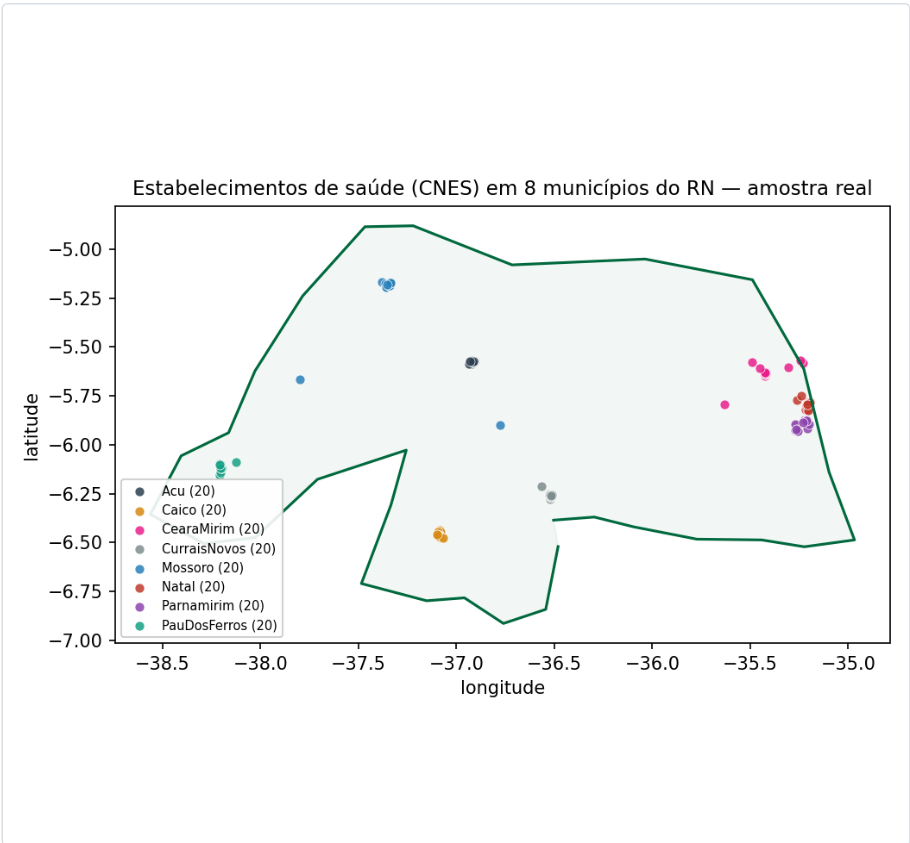

Este mapa combina, em uma única figura, três das quatro fontes de dados desta aula: o contorno do estado veio de uma API REST (Malhas do IBGE, em GeoJSON) e os pontos vieram de um arquivo (o snapshot salvo da API do CNES). É o fechamento natural do laboratório: os mesmos conceitos de aquisição de dados, aplicados até a etapa de visualização.


> **Parte avaliativa desta apostila → [atividades.ipynb](atividades.ipynb).**

### Apêndice A - Colinha de comandos

### Arquivos e formatos

| Comando | Faz |
|----------------------------------------------------------------|----------------------------------------------------------------|
| pd.read_csv(caminho, sep=";", decimal=",", encoding="utf-8") | Lê CSV declarando separador, decimal e encoding explicitamente |
| df.to_json(caminho, orient="records") / pd.read_json(caminho) | Grava/lê JSON tabular |
| pd.json_normalize(lista_de_dicts) | Achata JSON aninhado em colunas |
| df.to_parquet(caminho, index=False) / pd.read_parquet(caminho) | Grava/lê Parquet (colunar, binário, requer pyarrow ) |
| ET.ElementTree(root).write(caminho, encoding="utf-8") | Grava uma árvore XML montada com xml.etree.ElementTree |

### Banco de dados

| Comando | Faz |
|------------------------------------------------------------|---------------------------------------------------------------|
| con = sqlite3.connect("arquivo.db") (ou ":memory:" ) | Abre conexão com um banco SQLite em arquivo ou em memória |
| df.to_sql("tabela", con, index=False, if_exists="replace") | Grava um DataFrame como tabela do banco |
| pd.read_sql("SELECT ...", con) | Executa uma consulta SQL e devolve o resultado como DataFrame |

### API REST e web scraping

| Comando | Faz |
|----------------------------------------------|-----------------------------------------------------------|
| requests.get(url, params={...}, timeout=10) | Faz uma requisição GET com parâmetros de query string |
| resposta.raise_for_status() | Levanta exceção se o status HTTP indicar erro (4xx/5xx) |
| resposta.json() | Converte o corpo da resposta em listas/dicionários Python |
| Paginação: repetir com offset=0, 20, 40, ... | Contorna um limit máximo imposto pelo servidor |
| BeautifulSoup(html, "html.parser") | Faz o parsing de um HTML |
| soup.find("table", {"class": "wikitable"}) | Localiza o primeiro elemento que casa com o seletor |
| tabela.find_all("tr")[1:] | Todas as linhas, pulando o cabeçalho |
| https://dominio.com/robots.txt | Checar antes de qualquer scraping |

### Apêndice B - Referências e leituras recomendadas

- MINISTÉRIO DA SAÚDE. API de Dados Abertos - CNES (Cadastro Nacional de Estabelecimentos de Saúde) . apidadosabertos.saude.gov.br . Fonte dos dados de

estabelecimentos de saúde usados nesta aula.

- IBGE. API de Malhas Territoriais . servicodados.ibge.gov.br . Fonte do contorno geográfico do Rio Grande do Norte (GeoJSON) usado no mapa desta aula.
- WIKIPÉDIA. Lista de municípios do Rio Grande do Norte . pt.wikipedia.org . Conteúdo sob licença Creative Commons Atribuição-CompartilhaIgual 4.0 (CC BY-SA 4.0).
- BRASIL. Lei nº 12.527, de 18 de novembro de 2011 (Lei de Acesso à Informação) - base legal do regime de dados abertos governamentais citado nesta aula.
- McKINNEY, Wes. Python para Análise de Dados . 3. ed. São Paulo: Novatec, 2023. Capítulo 6 (Leitura e escrita de dados em diferentes formatos). A 3ª edição em inglês está disponível gratuitamente em wesmckinney.com/book .
- PANDAS DEVELOPMENT TEAM. Pandas User Guide - seções IO tools (text, CSV , HDF5, …) e SQL queries . pandas.pydata.org/docs/user\_guide/
- REQUESTS. Requests: HTTP for Humans - documentação oficial da biblioteca requests . requests.readthedocs.io
- RICHARDSON, Leonard. Beautiful Soup Documentation . www.crummy.com/software/BeautifulSoup/bs4/doc

### O que vem na próxima aula

Limpeza e tratamento de dados ausentes : a Unidade 2 continua a partir daqui - com os dados já adquiridos e sua proveniência registrada, a próxima aula trata de como identificar, entender e tratar valores ausentes, duplicados e inconsistentes antes de qualquer análise.

Aula 06 - Processos e Fontes de Dados · Análise e Ciência de Dados · Especialização em Ciência de Dados · IFRN

---
## Slides — Aula 06: Processos e Fontes de Dados

> Convertido de [`Aula06_Slides_Fontes_de_Dados.pptx`](Aula06_Slides_Fontes_de_Dados.pptx) (o original está nesta pasta — confira nele figuras e diagramação).

UNIDADE 2 — AQUISIÇÃO E PREPARAÇÃO DE DADOS

Aula 06

Processos e Fontes de Dados

Arquivos • Bancos de Dados • APIs REST • Web Scraping

Especialização em Ciência de Dados — IFRN  


Prof. Plácido Antônio de Souza Neto

ROTEIRO DA AULA

Agenda e objetivos

- Reconhecer as quatro famílias de fontes de dados e o custo/risco de cada uma
- Ler arquivos evitando armadilhas reais de encoding e separador decimal
- Conectar Python a bancos relacionais via SQL (sqlite3, pandas)
- Consumir APIs REST com requests e reconhecer armadilhas reais de filtro e paginação
- Fazer web scraping com responsabilidade (robots.txt, Termos de Uso)
- Comparar formatos de dados e registrar licença e proveniência

NESTA AULA

1

Panorama das 4 fontes

2

Arquivos

3

Bancos de dados

4

APIs REST

5

Web scraping

6

Formatos, licença e proveniência

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

2

PANORAMA

As quatro famílias de fontes de dados

1

2

3

4

Arquivos

Bancos de dados

APIs REST

Web scraping

CSV, Excel, JSON, Parquet, XML.

Dado "parado" — leitura direta,

sem rede, sem autenticação.

→

PostgreSQL, MySQL, SQLite…

Conexão + permissões, mas

fala SQL — estável e estruturado.

→

Endpoints HTTP sob demanda.

Depende de um serviço de

terceiros no ar, com limites.

→

Extrai HTML feito para humanos.

Último recurso: estrutura muda

e território legal é delicado.

Esforço/risco: baixo

Esforço/risco: moderado

Esforço/risco: alto

Esforço/risco: mais alto

A ordem não é aleatória: reflete o quanto de trabalho e risco cada fonte exige.

Estudo de caso desta aula — CNES: os mesmos estabelecimentos de saúde do Rio Grande do Norte aparecem nas quatro formas: arquivo JSON em disco, tabela em banco SQLite, resposta de API REST pública e tabela raspada da Wikipédia — para deixar concreto o que muda (e o que não muda) de uma fonte para outra.

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

3

FONTE 1 DE 4

Arquivos: a fonte mais simples (e onde ela falha)

pd.read\_csv, pd.read\_excel, pd.read\_json… mas "bem-comportado" é a exceção, não a regra.

Arquivo como cache de outra fonte

Qual o encoding?

Salvar em arquivo o resultado de uma chamada de API transforma uma fonte instável (rede) em reproduzível — mas é uma fotografia: se a fonte mudar amanhã, o arquivo de hoje não reflete isso.

utf-8 é o padrão atual; sistemas legados brasileiros costumam salvar em latin-1 (iso-8859-1). Erro silencioso: "informação" vira "informaÃ§Ã£o".

Separador e decimal?

Planilhas brasileiras usam ; como separador de coluna, porque a vírgula já é o separador decimal — o oposto do padrão americano.

import json

with open("dados/cnes\_rn\_amostra.json",

          "w", encoding="utf-8") as f:

    json.dump(resposta\_da\_api, f,

              ensure\_ascii=False, indent=1)

A 1ª linha é cabeçalho?

Nem sempre — alguns exports trazem metadados antes da tabela (resolvido com skiprows).

Registre sempre a data da coleta junto com o arquivo salvo.

Cabe na memória?

Um CSV de 50 GB não vira DataFrame inteiro: leitura em blocos (chunksize) ou formato colunar (Parquet).

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

4

FONTE 2 DE 4

Bancos de dados: quando o dado mora em tabelas

- O dado vive em tabelas relacionadas; a forma de acessá-lo é uma consulta SQL, não um método de leitura de arquivo
- O banco filtra, agrega e junta os dados antes de entregá-los — muitas vezes mais eficiente que trazer tudo para o Python
- Cada banco tem seu driver: psycopg2 (PostgreSQL), pymysql (MySQL), pyodbc (SQL Server), sqlite3 (biblioteca padrão)

Python + SQLite (o exemplo desta aula)

import sqlite3

import pandas as pd

conexao = sqlite3.connect("dados/exemplo.db")

df = pd.read\_sql(

    "SELECT * FROM estabelecimentos "

    "WHERE municipio = 'Natal'", conexao)

df.to\_sql("estabelecimentos", conexao,

          index=False, if\_exists="replace")

SQL ou Pandas — quem faz o quê?

- Tabela com 200 milhões de linhas? Filtrar com WHERE dentro do banco evita transportar dados que serão descartados
- Resultado já pequeno e em memória? Pandas é mais produtivo para exploração, limpeza e visualização

read\_sql traz o resultado como DataFrame; to\_sql grava um DataFrame como tabela — o mesmo GROUP BY por município e tipo que a Aula 05 fez em Pandas, agora em SQL.

Uma API também pode ser "um banco disfarçado" — mas sem schema livre, sem JOIN, e sujeita às regras do provedor.

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

5

FONTE 3 DE 4

APIs REST: dados sob demanda, com regras do dono

Um contrato: o provedor define endpoints, parâmetros aceitos e o formato de resposta (quase sempre JSON).

Anatomia de uma requisição

params vira a query string da URL (?codigo\_municipio=...&amp;limit=20)

import requests

url = "https://apidadosabertos.saude.gov.br/"

      "cnes/estabelecimentos"

parametros = {"codigo\_municipio": 240810,

              "limit": 20}

resposta = requests.get(url,

               params=parametros, timeout=10)

resposta.raise\_for\_status()

dados = resposta.json()

.json() converte o corpo da resposta em listas e dicionários Python

raise\_for\_status() levanta exceção se o servidor devolveu erro 4xx/5xx

Autenticação e rate limiting

Esta API é pública e sem chave — a maioria exige API key/token OAuth (header Authorization: Bearer). Exceder o limite de requisições costuma devolver HTTP 429; um bom cliente espera e tenta de novo (backoff).

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

6

DESCOBERTA TESTANDO A API DO CNES

APIs REST: duas armadilhas reais

Nenhuma delas gera um erro — as duas exigem inspecionar o retorno com atenção.

1

Parâmetros aceitos, mas ignorados

2

Limite de página fixo pelo servidor

O que acontece  


Filtrar por uf=RN ou codigo\_uf=24 não gera erro — a API devolve dados de qualquer estado, como se o filtro não existisse.



Como resolver  


Só codigo\_municipio (código IBGE de 6 dígitos) filtra de verdade. Lição: sempre inspecionar o retorno, nunca supor que um parâmetro "razoável" funcionou só porque não deu erro.

O que acontece  


Pedir limit=1000 devolve no máximo 20 registros — o servidor ignora limites maiores que o seu teto interno.



Como resolver  


Solução: paginar repetindo a chamada com offset=20, offset=40… até a resposta vir vazia.

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

7

FONTE 4 DE 4 — ÚLTIMO RECURSO

Web scraping: quando usar, com responsabilidade

Extrair dados do HTML de uma página feita para humanos lerem, não para máquinas.

BeautifulSoup: extraindo uma tabela

Antes de escrever uma linha de código

- Existe uma API para os mesmos dados? (aba Network do navegador, ou API oficial)
- O que diz o robots.txt do site?
- O que dizem os Termos de Uso? (violá-los tem consequências, mesmo sem violar o robots.txt)
- Sob que licença está o conteúdo? Acessível não é sinônimo de livre para reuso

from bs4 import BeautifulSoup

import requests

html = requests.get(url).text

sopa = BeautifulSoup(html, "html.parser")

tabela = sopa.find("table",

                    {"class": "wikitable"})

linhas = [

  [td.get\_text(strip=True)

   for td in tr.find\_all("td")]

  for tr in tabela.find\_all("tr")[1:]

]

Ética em campo: identifique seu programa no cabeçalho HTTP (User-Agent), espace as requisições no tempo e nunca sobrecarregue o servidor. A Wikipédia (usada nesta aula) publica sob CC BY-SA e permite reuso automatizado dentro de limites razoáveis — um dos poucos casos com base legal e ética confortável. Diferente de uma API, o HTML pode mudar sem aviso: isole o scraper em módulo próprio.

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

8

DEPOIS DA FONTE, O FORMATO

Formatos de dados comparados

Mesmo conjunto de dados do CNES, gravado em formatos diferentes — tamanhos reais medidos nesta aula.

| Formato | Estrutura | Base | Tamanho real |
|--------------------------|--------------------------------------------|---------------------------|----------------------|
| Parquet | Colunar, binário, comprimido | 160 registros | 7.868 bytes (menor) |
| CSV | Linhas, sem tipos nem metadados | 160 registros | 12.451 bytes |
| JSON (bruto + metadados) | Objetos aninhados, chave-valor | 160 registros | 36.809 bytes |
| XML | Tags de abertura/fechamento — mais verboso | 3 registros (ilustrativo) | 694 bytes |

- Parquet vence por ser colunar e comprimido: menor arquivo e leitura seletiva de colunas, sem abrir o arquivo inteiro — por isso é o preferido para grandes volumes (Spark, PyArrow, data lakes).
- XML: 694 bytes para só 3 linhas (~231 bytes/registro) já é mais verboso que os 160 registros inteiros em CSV (~78 bytes/registro) — o custo das tags de abertura/fechamento.
- GeoJSON é um caso especial de JSON para dados geográficos (próximo slide).

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

9

UM CASO ESPECIAL DE JSON

GeoJSON e mapas

- JSON com estrutura padronizada para representar pontos, linhas e polígonos geográficos, com coordenadas de longitude e latitude
- Formato de troca padrão entre ferramentas de mapas: QGIS, Leaflet, geopandas
- Usado nesta aula: o contorno do Rio Grande do Norte, obtido da API de Malhas do IBGE
- Combinado com os pontos dos estabelecimentos do CNES, gera o mapa real da próxima página

polígono (contorno RN)

+ pontos (estabelecimentos)

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

10

ENTREGÁVEL DA AULA

O mapa real desta aula

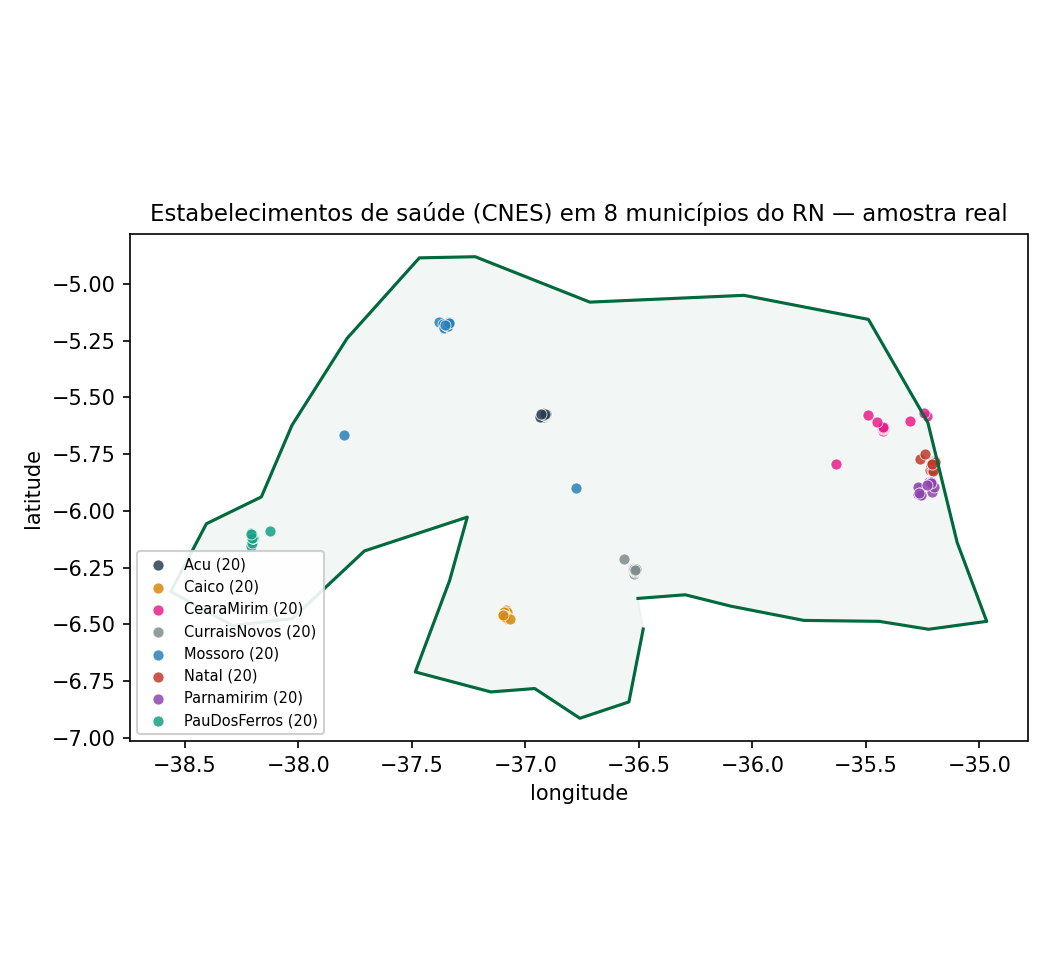

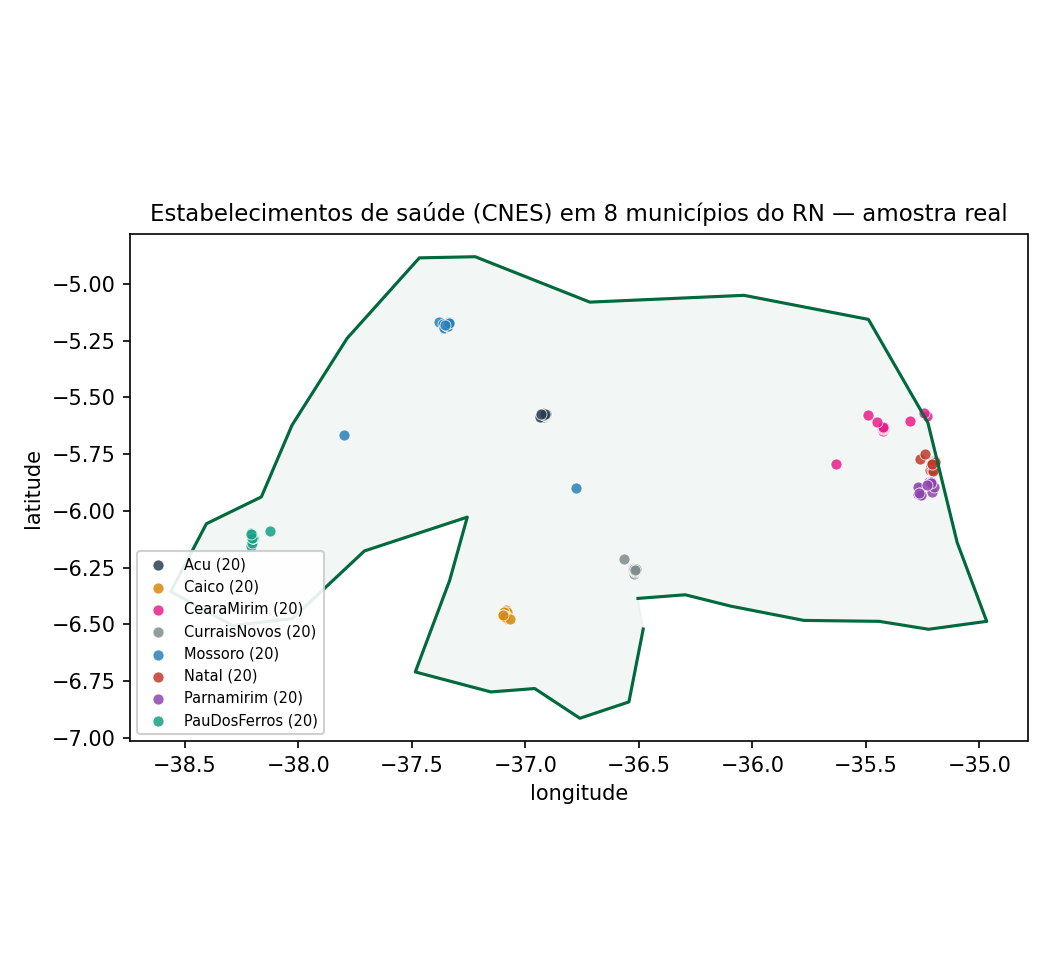

Dados reais desta aula

- 160 estabelecimentos de saúde, 8 municípios
- 20 registros por município (limite fixo do servidor da API)
- Açu, Caicó, Ceará-Mirim, Currais Novos, Mossoró, Natal, Parnamirim, Pau dos Ferros

Fontes

Ministério da Saúde — API de Dados Abertos (CNES)  


apidadosabertos.saude.gov.br/cnes/estabelecimentos



IBGE — API de Malhas (contorno territorial do RN)



Coletado em 2026-09-28 · Licença: dados abertos governamentais (Lei 12.527/2011)

Estabelecimentos de saúde (CNES) em 8 municípios do RN, sobre o contorno territorial (IBGE)

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

11

SOB QUE REGRAS POSSO USAR O DADO?

Licença: o que você pode fazer com o dado

Lei de Acesso à Informação

Creative Commons (CC)

Termos proprietários

Dados públicos governamentais

Wikipédia usa CC BY-SA nesta aula

APIs comerciais, redes sociais

CNES e IBGE, usados nesta aula. Lei 12.527/2011 — via de regra, uso livre, inclusive comercial, com boa prática de citar a fonte.

BY exige atribuição · SA (share-alike) exige mesma licença nos derivados · NC proíbe uso comercial · ND proíbe modificações.

Podem proibir redistribuição e uso comercial, ou exigir que os dados sejam apagados após um prazo.

Ausência de licença explícita não significa domínio público — na dúvida, trate o dado como protegido por padrão.

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

12

A RASTREABILIDADE QUE SUSTENTA A CONFIANÇA

Proveniência: registrar de onde veio o dado

- Um dado sem proveniência registrada é, na prática, inutilizável para qualquer decisão séria: ninguém pode auditar, reproduzir ou saber se ainda é válido
- Registrar proveniência custa poucas linhas e paga dividendos toda vez que alguém — inclusive você, seis meses depois — precisar responder "de onde veio esse número?"

Exemplo real desta aula: metadados junto dos dados

{

  "fonte": "Ministério da Saúde —

            API de Dados Abertos (CNES)",

  "endpoint": "apidadosabertos.saude.gov.br/

               cnes/estabelecimentos",

  "data\_coleta": "2026-09-28",

  "licenca": "Dados abertos governamentais

              (Lei 12.527/2011)",

  "registros": [ ... ]

}

As quatro perguntas de todo processo de aquisição

- De onde veio? (endpoint, URL, arquivo, banco e tabela)
- Quando foi coletado? (dados mudam; a amostra de hoje pode não valer amanhã)
- Sob que licença posso usá-lo?
- O que fazer se a fonte mudar ou cair? (cache, versionamento, tratamento de erro)

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

13

FECHANDO O RACIOCÍNIO

Checklist: qual fonte usar, quando?

1

Existe um arquivo pronto?

Use-o direto — CSV, Excel, JSON, Parquet. Confira encoding e separador antes de tudo.

↓

2

Não, mas há um banco acessível?

Conecte com o driver certo e filtre com SQL (WHERE) antes de trazer para o Python.

↓

3

Não, mas existe uma API?

Use requests + params. Teste se os filtros realmente funcionam e cuide da paginação.

↓

4

Nada disso?

Web scraping como último recurso: robots.txt, Termos de Uso, módulo isolado.

Sempre, em qualquer caso: registre fonte, data da coleta e licença.

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

14

DEPOIS DA AULA

Próximos passos

Exercício prático

Formulário avaliativo

- Aplique o pipeline de aquisição de dados a um caso à sua escolha
- Identifique a família de fonte mais adequada (arquivo, banco, API ou scraping)
- Leia os dados tratando encoding/separador (se arquivo) ou testando parâmetros e paginação (se API)
- Registre fonte, data da coleta e licença junto dos dados obtidos — entregue até 13/10/2026

10

questões objetivas

- Cobrem: encoding, paginação, parâmetros ignorados, checagens antes de scraping, formatos (CSV/JSON/XML/Parquet/GeoJSON), licenças CC e proveniência
- Prazo de envio: até 13/10/2026 (15 dias após esta aula)

Aula 06 — Processos e Fontes de Dados | Análise e Ciência de Dados — IFRN

15

Dúvidas?

Obrigado pela atenção — Aula 06: Processos e Fontes de Dados

Próxima aula

Unidade 2 continua com limpeza e tratamento de dados ausentes, partindo do princípio de que os dados já chegaram de forma íntegra e rastreável.

Prof. Plácido Antônio de Souza Neto  


placido.neto@ifrn.edu.br  


Especialização em Ciência de Dados — IFRN